In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/sample_submission.csv
/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/train.csv
/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/test.csv


In [5]:
import pandas as pd
train = pd.read_csv("/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/train.csv")
test = pd.read_csv("/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/test.csv")

In [6]:
x_train = train.drop(columns=["price_tier"])
y_train = train["price_tier"]
x_test = test.copy()

In [7]:
x_train = x_train.drop(columns=["space_id"])
x_test = x_test.drop(columns=["space_id"])

In [8]:
test.head()

,space_id,operator_ref,operator_platform_age_years,operator_platform_age_months,operator_active_years,operator_active_months,operator_class,operator_certified,operator_portfolio_size,operator_has_avatar,...,score_support,score_access,score_value,compliance_status,operator_metro_units,operator_metro_whole,operator_metro_private,operator_metro_shared,reviews_per_month,metro
0,0,Praklar,2.0,11.0,2.0,11.0,unverified_operator,t,29.0,t,...,9.82,9.16,9.60,unlicensed,29,29,0,0,3.97,MTR-07
1,1,Draren,2.0,6.0,2.0,2.0,unverified_operator,f,8.0,t,...,NaN,NaN,NaN,licensed,8,1,7,0,NaN,MTR-13
2,2,Sinnovara,3.0,4.0,3.0,3.0,managed_operator,f,33.0,t,...,10.00,10.00,10.00,licensed,33,33,0,0,0.27,MTR-16
3,3,Fehinn,5.0,7.0,5.0,6.0,unverified_operator,f,3.0,t,...,7.70,8.16,8.46,unlicensed,3,0,3,0,0.24,MTR-12
4,4,Rothass,11.0,2.0,11.0,1.0,independent_operator,f,90.0,t,...,9.78,9.26,9.26,unlicensed,27,1,26,0,1.99,MTR-09


In [9]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import f1_score
TARGET, ID = "price_tier", "space_id"
feat = [c for c in train.columns if c not in (TARGET, ID)]
num = train[feat].select_dtypes("number").columns
cat = train[feat].select_dtypes(exclude="number").columns

In [10]:
print("train:", train.shape, "test:", test.shape)
print("only in train:", set(train.columns) - set(test.columns))
print("only in test:", set(test.columns) - set(train.columns))
print(train.dtypes.value_counts())
print(train.dtypes.to_string())
print("space_id unique:", train[ID].is_unique)

train: (279746, 60) test: (114538, 59)
only in train: {'price_tier'}
only in test: set()
float64    26
int64      17
object     17
Name: count, dtype: int64
space_id                          int64
operator_ref                     object
operator_platform_age_years     float64
operator_platform_age_months    float64
operator_active_years           float64
operator_active_months          float64
operator_class                   object
operator_certified               object
operator_portfolio_size         float64
operator_has_avatar              object
operator_id_verified             object
zone                             object
borough                          object
geo_lat                         float64
geo_lon                         float64
space_class                      object
access_type                      object
max_seats                         int64
utility_rooms                   float64
zones                           float64
workstations                    float64
fac

price_tier
1    66889
2    81530
3    60839
4    70488
Name: count, dtype: int64
price_tier
1    0.239
2    0.291
3    0.217
4    0.252
Name: proportion, dtype: float64


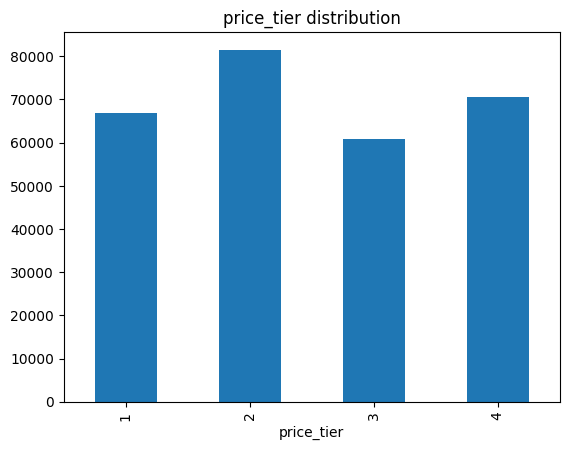

Majority-class macro F1: 0.1128361695767225


In [11]:
print(train[TARGET].value_counts().sort_index())
print(train[TARGET].value_counts(normalize=True).sort_index().round(3))
train[TARGET].value_counts().sort_index().plot(kind="bar", title="price_tier distribution"); plt.show()
maj = train[TARGET].mode()[0]
print("Majority-class macro F1:", f1_score(train[TARGET], [maj]*len(train), average="macro"))

                              train_%  test_%
borough                         76.66   75.12
score_value                     19.39   18.73
score_access                    19.39   18.73
score_onboarding                19.39   18.74
score_accuracy                  19.39   18.73
score_support                   19.39   18.73
last_review_date                19.39   18.73
reviews_per_month               19.39   18.73
score_condition                 19.39   18.73
first_review_date               19.39   18.73
score_overall                   19.39   18.73
zones                           17.31   18.42
utility_rooms                   10.69   10.59
workstations                     6.71    7.04
operator_active_years            0.22    0.19
operator_active_months           0.22    0.19
operator_has_avatar              0.22    0.19
operator_ref                     0.22    0.19
operator_id_verified             0.22    0.19
operator_platform_age_months     0.22    0.19
operator_platform_age_years      0

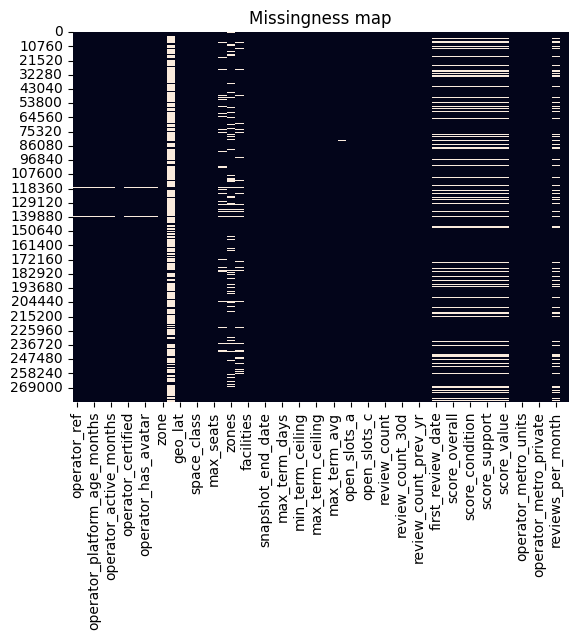

                              operator_ref  operator_platform_age_years  \
operator_ref                          1.00                         1.00   
operator_platform_age_years           1.00                         1.00   
operator_platform_age_months          1.00                         1.00   
operator_active_years                 1.00                         1.00   
operator_active_months                1.00                         1.00   
operator_certified                    1.00                         1.00   
operator_portfolio_size               1.00                         1.00   
operator_has_avatar                   1.00                         1.00   
operator_id_verified                  1.00                         1.00   
borough                              -0.05                        -0.05   
utility_rooms                         0.13                         0.13   
zones                                 0.10                         0.10   
workstations             

In [12]:
miss = pd.DataFrame({"train_%": train.isna().mean()*100, "test_%": test.isna().mean()*100})
print(miss[(miss > 0).any(axis=1)].sort_values("train_%", ascending=False).round(2))
sns.heatmap(train[feat].isna(), cbar=False); plt.title("Missingness map"); plt.show()

mc = train[feat].columns[train[feat].isna().any()]
print(train[mc].isna().corr().round(2))                       # do columns go missing together?
for c in mc[:8]:
    print(c, train.groupby(train[c].isna())[TARGET].value_counts(normalize=True).unstack().round(3))

In [13]:
X = train[feat]
print("exact duplicate rows:", X.duplicated().sum())
print("conflicting duplicates:", train[X.duplicated(keep=False)].groupby(feat, dropna=False)[TARGET].nunique().gt(1).sum())

def col(*names):  # helper: first matching column name
    return [c for c in train.columns if all(n in c for n in names)]
print("month cols:", col("months"))
for c in col("months"): print(c, "max =", train[c].max())
print("scores outside 0-10:", {c: ((train[c]<0)|(train[c]>10)).sum() for c in train.columns if c.startswith("score_")})

if {"operator_metro_units","operator_metro_whole","operator_metro_private","operator_metro_shared"} <= set(train.columns):
    s = train[["operator_metro_whole","operator_metro_private","operator_metro_shared"]].sum(axis=1)
    print("units != whole+private+shared:", (train["operator_metro_units"] != s).sum())
    print("metro units > portfolio:", (train["operator_metro_units"] > train["operator_portfolio_size"]).sum())
print("active > platform (years):", (train["operator_active_years"] > train["operator_platform_age_years"]).sum())
print(pd.crosstab(train["operator_class"], train["operator_certified"]))

print("negatives:", (train[num] < 0).sum()[lambda s: s>0].to_dict())
print("near-constant:", [c for c in feat if train[c].value_counts(normalize=True, dropna=False).iloc[0] > 0.99])

exact duplicate rows: 1160
conflicting duplicates: 43
month cols: ['operator_platform_age_months', 'operator_active_months']
operator_platform_age_months max = 11.0
operator_active_months max = 11.0
scores outside 0-10: {'score_overall': np.int64(0), 'score_accuracy': np.int64(0), 'score_condition': np.int64(0), 'score_onboarding': np.int64(0), 'score_support': np.int64(0), 'score_access': np.int64(0), 'score_value': np.int64(0)}
units != whole+private+shared: 3428
metro units > portfolio: 1849
active > platform (years): 3
operator_certified        f      t
operator_class                    
independent_operator  63402  48485
managed_operator      26970  13416
unverified_operator   89863  37006
negatives: {'geo_lat': 22706, 'geo_lon': 232422}
near-constant: ['bookable']


                                 count      mean          std     min     25%  \
operator_platform_age_years   279142.0      6.79         4.19    0.00    3.00   
operator_platform_age_months  279142.0      5.45         3.49    0.00    2.00   
operator_active_years         279140.0      5.08         4.04    0.00    2.00   
operator_active_months        279140.0      5.30         3.48    0.00    2.00   
operator_portfolio_size       279142.0     49.47       332.75    0.00    1.00   
geo_lat                       279746.0     77.77        37.51   -4.82   68.04   
geo_lon                       279746.0    -35.14        57.17 -123.75  -76.56   
max_seats                     279746.0      3.63         2.28    1.00    2.00   
utility_rooms                 249847.0      1.36         0.81    0.50    1.00   
zones                         231332.0      1.66         1.09    0.00    1.00   
workstations                  260963.0      2.16         1.71    1.00    1.00   
min_term_days               

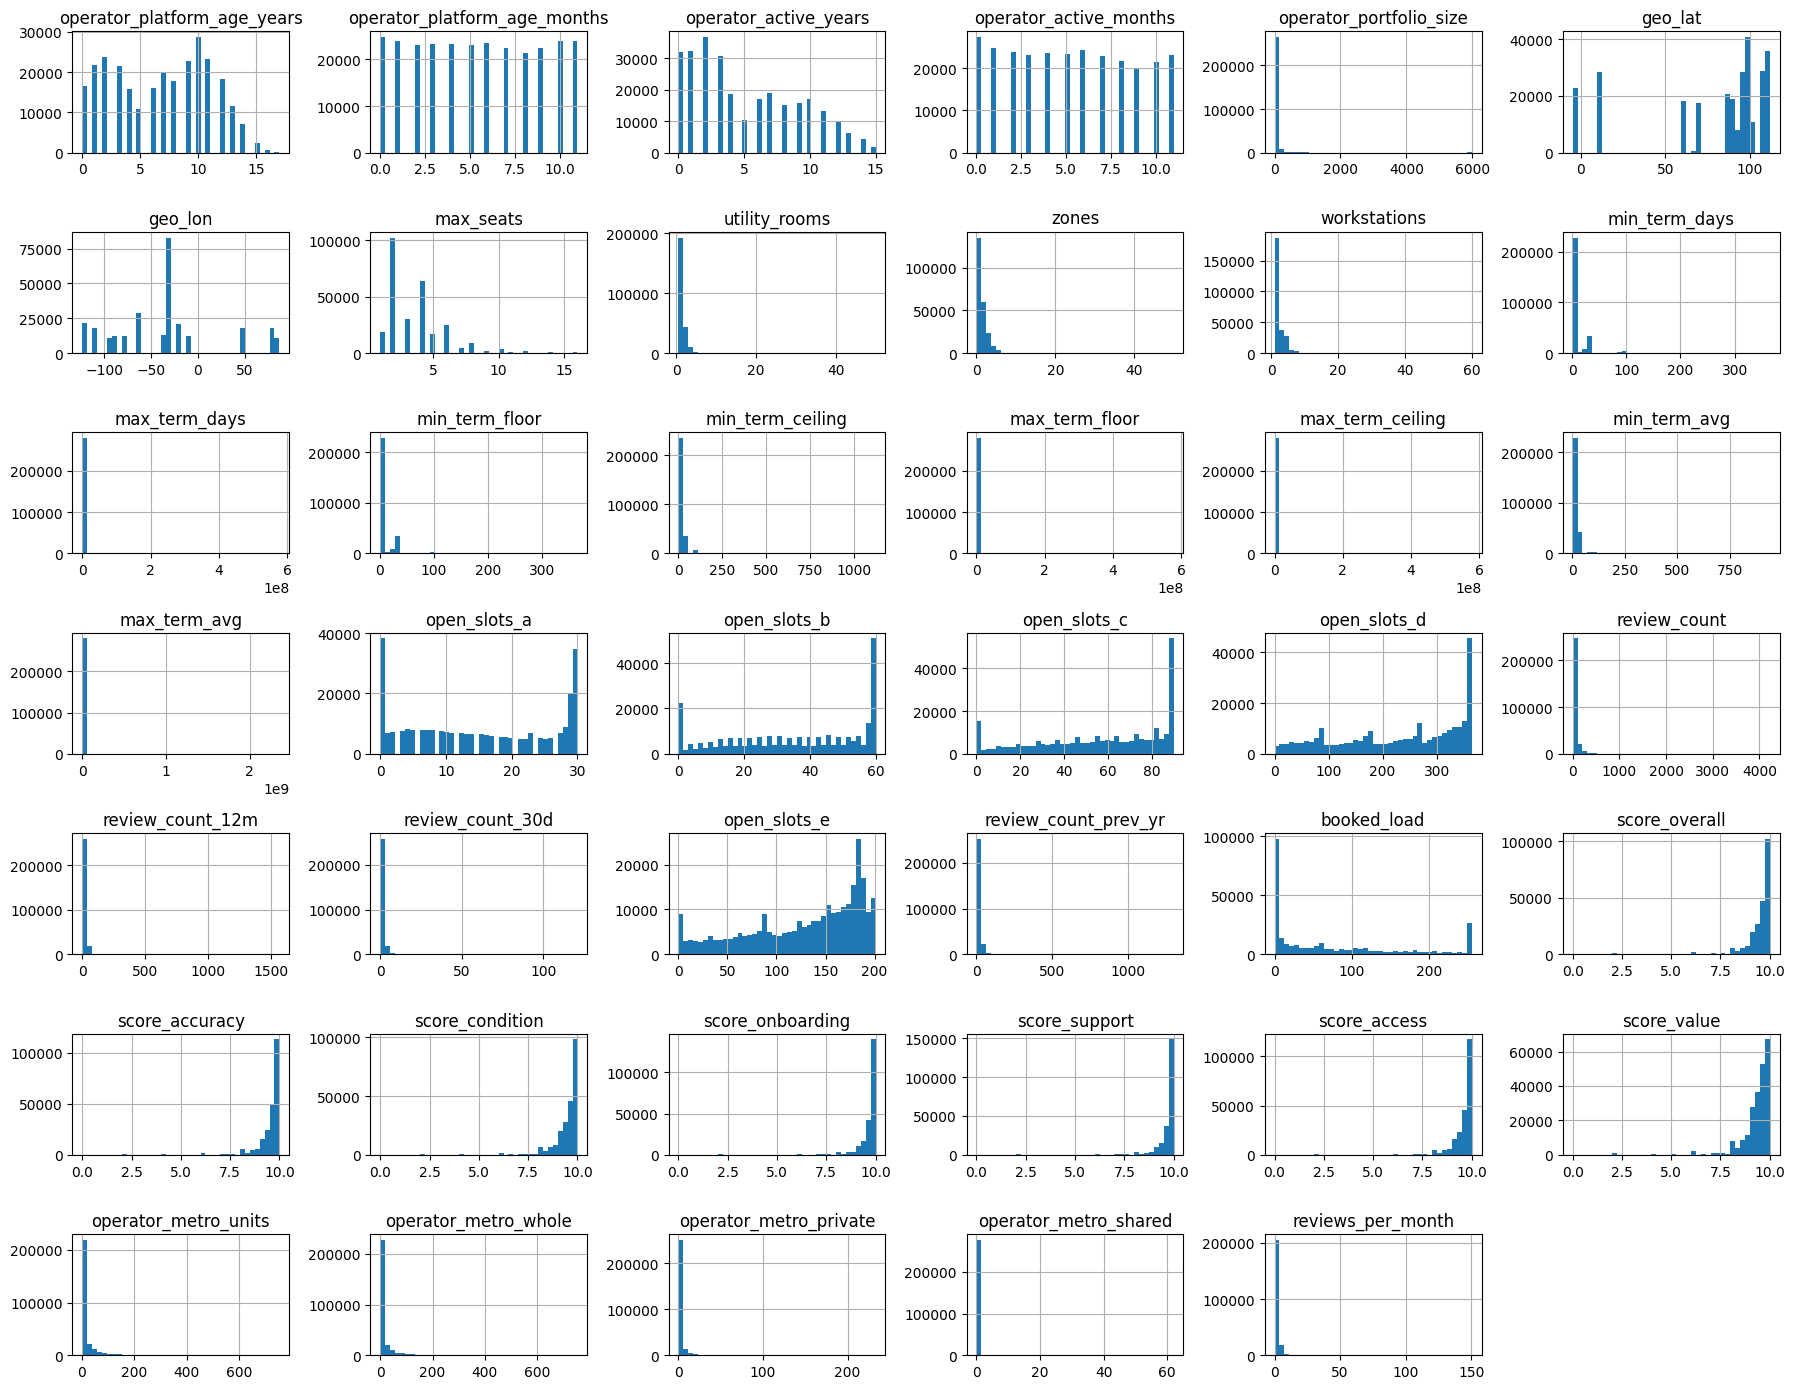

IQR outlier % per column:
 min_term_ceiling           20.63
min_term_avg               20.45
min_term_floor             18.98
min_term_days              18.98
geo_lat                    18.32
operator_metro_private     17.79
operator_metro_whole       16.07
operator_metro_units       14.35
operator_portfolio_size    14.22
review_count_30d           13.85
geo_lon                    10.38
review_count               10.17
review_count_prev_yr        9.92
review_count_12m            6.98
score_support               6.88
dtype: float64
skewed columns (|skew|>1): ['operator_portfolio_size', 'geo_lat', 'max_seats', 'utility_rooms', 'zones', 'workstations', 'min_term_days', 'max_term_days', 'min_term_floor', 'min_term_ceiling', 'max_term_floor', 'max_term_ceiling', 'min_term_avg', 'max_term_avg', 'review_count', 'review_count_12m', 'review_count_30d', 'review_count_prev_yr', 'score_overall', 'score_accuracy', 'score_condition', 'score_onboarding', 'score_support', 'score_access', 'score_value'

In [14]:
print(train[num].describe().T.assign(skew=train[num].skew()).round(2))
train[num].hist(bins=40, figsize=(18,14)); plt.tight_layout(); plt.show()
q1, q3 = train[num].quantile(.25), train[num].quantile(.75); iqr = q3 - q1
out = (((train[num] < q1-1.5*iqr) | (train[num] > q3+1.5*iqr)).mean()*100).round(2)
print("IQR outlier % per column:\n", out.sort_values(ascending=False).head(15))
print("skewed columns (|skew|>1):", train[num].skew()[lambda s: s.abs()>1].index.tolist())

In [15]:
for c in cat:
    print(f"\n{c}: {train[c].nunique()} unique")
    print(train[c].value_counts(normalize=True).head(8).round(3))
# operator overlap between train and test
print("test operators also in train:", test["operator_ref"].isin(train["operator_ref"]).mean().round(3))
print("listings per operator:\n", train["operator_ref"].value_counts().describe())


operator_ref: 41903 unique
operator_ref
Bessstu       0.005
Zianovath     0.004
Nalsto        0.004
Dessselra     0.004
Stianianlo    0.003
Klynfova      0.003
Sinnovara     0.003
Zelten        0.003
Name: proportion, dtype: float64

operator_class: 3 unique
operator_class
unverified_operator     0.456
independent_operator    0.400
managed_operator        0.144
Name: proportion, dtype: float64

operator_certified: 2 unique
operator_certified
f    0.646
t    0.354
Name: proportion, dtype: float64

operator_has_avatar: 2 unique
operator_has_avatar
t    0.958
f    0.042
Name: proportion, dtype: float64

operator_id_verified: 2 unique
operator_id_verified
t    0.986
f    0.014
Name: proportion, dtype: float64

zone: 1380 unique
zone
ZN-0923    0.039
ZN-0779    0.034
ZN-0948    0.031
ZN-0536    0.017
ZN-1039    0.013
ZN-0454    0.013
ZN-0812    0.011
ZN-0315    0.010
Name: proportion, dtype: float64

borough: 55 unique
borough
BRG-18    0.163
BRG-30    0.141
BRG-22    0.134
BRG-14    0.082

In [ ]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
use = [c for c in feat if c != "operator_ref"]
Xe = train[use].copy()
for c in Xe.select_dtypes(exclude="number"): Xe[c] = Xe[c].astype("category").cat.codes
Xe = Xe.fillna(Xe.median())

mi = pd.Series(mutual_info_classif(Xe, train[TARGET], random_state=0), index=use).sort_values(ascending=False)
print("Top 10 by mutual information:\n", mi.head(10))
rf = RandomForestClassifier(300, n_jobs=-1, random_state=0, class_weight="balanced").fit(Xe, train[TARGET])
print("Top 10 by RF importance:\n", pd.Series(rf.feature_importances_, index=use).sort_values(ascending=False).head(10))

for c in mi.head(6).index:
    if c in num: sns.boxplot(data=train, x=TARGET, y=c); plt.title(c); plt.show()
    else: pd.crosstab(train[c], train[TARGET], normalize="index").plot(kind="bar", stacked=True, title=c); plt.show()

Top 10 by mutual information:
 facilities      0.322189
zone            0.233369
geo_lon         0.196790
geo_lat         0.196487
metro           0.155214
max_seats       0.154741
zones           0.127906
space_class     0.100464
workstations    0.094839
access_type     0.076342
dtype: float64
Top 10 by RF importance:
 geo_lat                0.080752
geo_lon                0.060190
max_seats              0.042092
zones                  0.039041
facilities             0.029296
metro                  0.026086
snapshot_end_date      0.024959
zone                   0.023683
snapshot_start_date    0.022602
open_slots_d           0.022170
dtype: float64


In [ ]:
corr = train[num].corr(method="spearman")
plt.figure(figsize=(14,11)); sns.heatmap(corr, cmap="coolwarm", center=0); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print(pairs[pairs.abs() > 0.7].sort_values(key=abs, ascending=False))

def eta2(c, n):
    s = train[n].fillna(train[n].median()); g = s.groupby(train[c])
    return (g.count()*(g.mean()-s.mean())**2).sum() / ((s-s.mean())**2).sum()
for c in ["operator_class", "compliance_status", "metro"]:
    print(c, {n: round(eta2(c, n), 3) for n in num[:8]})

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_val_predict

def add_feats(d):
    d = d.copy()
    d["platform_tenure"] = d["operator_platform_age_years"] + d["operator_platform_age_months"]/12
    d["active_tenure"]   = d["operator_active_years"] + d["operator_active_months"]/12
    d["inactive_gap"]    = d["platform_tenure"] - d["active_tenure"]
    u = d["operator_metro_units"].replace(0, np.nan)
    for p in ["whole", "private", "shared"]: d[f"share_{p}"] = d[f"operator_metro_{p}"] / u
    d["metro_share"] = d["operator_metro_units"] / d["operator_portfolio_size"].replace(0, np.nan)
    sc = [c for c in d.columns if c.startswith("score_")]
    d["has_reviews"] = d["reviews_per_month"].notna().astype(int)
    d["score_mean"] = d[sc].mean(axis=1)
    d["operator_freq"] = d["operator_ref"].map(pd.concat([train, test])["operator_ref"].value_counts())
    return d.drop(columns=["operator_ref"])

Xtr, Xte = add_feats(train.drop(columns=[TARGET, ID])), add_feats(test.drop(columns=[ID]))
y = train[TARGET]
nf = Xtr.select_dtypes("number").columns; cf = Xtr.select_dtypes(exclude="number").columns
pre = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), nf),
    ("cat", Pipeline([("i", SimpleImputer(strategy="most_frequent")),
                      ("o", OneHotEncoder(handle_unknown="ignore"))]), cf)])
base = Pipeline([("pre", pre), ("clf", RandomForestClassifier(300, n_jobs=-1, random_state=42, class_weight="balanced"))])

p1 = cross_val_predict(base, Xtr, y, cv=StratifiedKFold(5, shuffle=True, random_state=42))
print("Baseline macro F1 (stratified CV):", f1_score(y, p1, average="macro"))
p2 = cross_val_predict(base, Xtr, y, cv=GroupKFold(5), groups=train["operator_ref"])
print("Baseline macro F1 (grouped by operator):", f1_score(y, p2, average="macro"))

for c in nf[:10]:
    print(c, "train mean", round(Xtr[c].mean(), 2), "test mean", round(Xte[c].mean(), 2))

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression   # use LinearRegression/Ridge if regression
from sklearn.metrics import f1_score

# ---------- PLACEHOLDERS ----------
TRAIN_PATH = "/kaggle/input/<competition>/train.csv"
TEST_PATH  = "/kaggle/input/<competition>/test.csv"
TARGET     = "<target_column>"
ID_COLS    = []            # e.g. ["id"]
DATE_COLS  = []            # e.g. ["date"]
TEXT_COLS  = []            # free text columns
ORDINAL_COLS = {}          # e.g. {"size": ["S","M","L"]}
IS_CLASSIFICATION = True
# -----------------------------------

df = pd.read_csv(x_train); test = pd.read_csv(x_test)

# ===== Q1: overview / what needs preprocessing =====
print(df.shape); df.info()
num_cols = df.select_dtypes("number").columns.drop([TARGET]+ID_COLS, errors="ignore").tolist()
cat_cols = [c for c in df.select_dtypes(exclude="number").columns
            if c not in [TARGET]+ID_COLS+DATE_COLS+TEXT_COLS]
print("numeric:", num_cols); print("categorical:", cat_cols)
print(df.isna().mean().sort_values(ascending=False).head(15))
print(df[num_cols].describe().T[["min","mean","max","std"]])
print(df[cat_cols].nunique().sort_values(ascending=False))

# ===== Q2: duplicates, invalid, inconsistent =====
print("full duplicates:", df.duplicated().sum())
print("duplicate IDs:", df[ID_COLS].duplicated().sum() if ID_COLS else "n/a")
df = df.drop_duplicates()
for c in cat_cols:                                   # inconsistent labels (case/whitespace)
    before = df[c].nunique()
    df[c] = df[c].astype("string").str.strip().str.lower()
    test[c] = test[c].astype("string").str.strip().str.lower()
    print(c, before, "->", df[c].nunique())
# invalid values: inspect negatives/impossible values, then decide
for c in num_cols:
    n_neg = (df[c] < 0).sum()
    if n_neg: print(f"{c}: {n_neg} negative values")
# e.g. df.loc[df["age"] > 120, "age"] = np.nan    # mark invalid as missing

# ===== Q3: missing values =====
miss = df.isna().mean()
print(miss[miss > 0].sort_values(ascending=False))
sns.heatmap(df.isna(), cbar=False); plt.title("Missingness map"); plt.show()
# compare strategies on one column to show distribution effect
col = miss[miss > 0].index.intersection(num_cols)
if len(col):
    c = col[0]
    fig, ax = plt.subplots(1, 3, figsize=(14, 3))
    df[c].plot.hist(ax=ax[0], bins=30, title=f"{c} original")
    df[c].fillna(df[c].mean()).plot.hist(ax=ax[1], bins=30, title="mean impute")
    df[c].fillna(df[c].median()).plot.hist(ax=ax[2], bins=30, title="median impute")
    plt.show()
# final imputation is done inside the pipeline (Q9) to avoid leakage
# drop columns with very high missingness if justified:
# df = df.drop(columns=[c for c in df if df[c].isna().mean() > 0.6])

# ===== Q4: outliers =====
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return q1 - k*i, q3 + k*i
rows = []
for c in num_cols:
    lo, hi = iqr_bounds(df[c].dropna())
    rows.append((c, ((df[c] < lo) | (df[c] > hi)).mean(), df[c].skew()))
print(pd.DataFrame(rows, columns=["col","outlier_frac","skew"]).sort_values("outlier_frac", ascending=False))
df[num_cols[:6]].plot(kind="box", subplots=True, layout=(2,3), figsize=(12,6)); plt.show()
# example treatment: winsorise (fit bounds on train only)
caps = {c: df[c].quantile([.01, .99]).values for c in num_cols}
def winsorize(d):
    d = d.copy()
    for c,(lo,hi) in caps.items(): d[c] = d[c].clip(lo, hi)
    return d
df_w = winsorize(df)
# before/after plot for the most skewed column
c = max(num_cols, key=lambda x: abs(df[x].skew()))
fig, ax = plt.subplots(1,2,figsize=(10,3)); df[c].plot.hist(ax=ax[0],bins=40,title="before"); df_w[c].plot.hist(ax=ax[1],bins=40,title="after"); plt.show()

# ===== Q5: scaling =====
skewed = [c for c in num_cols if abs(df[c].skew()) > 1]
print("skewed (consider log/Robust):", skewed)
print(df[num_cols].agg(["min","max"]).T)   # shows differing ranges
# StandardScaler for ~symmetric cols, RobustScaler for skewed/outlier-heavy cols (set in pipeline)

# ===== Q6: encoding =====
print(df[cat_cols].nunique())
low  = [c for c in cat_cols if df[c].nunique() <= 10 and c not in ORDINAL_COLS]
high = [c for c in cat_cols if df[c].nunique() > 10  and c not in ORDINAL_COLS]
print("one-hot:", low, "| high-card (freq/target enc or rare grouping):", high, "| ordinal:", list(ORDINAL_COLS))
# OneHotEncoder(handle_unknown="ignore", min_frequency=0.01) groups rare + handles unseen categories

# ===== Q7: dates / text / ids =====
for c in DATE_COLS:
    for d in (df, test):
        d[c] = pd.to_datetime(d[c], errors="coerce")
        d[c+"_year"] = d[c].dt.year; d[c+"_month"] = d[c].dt.month; d[c+"_dow"] = d[c].dt.dayofweek
for c in TEXT_COLS:
    for d in (df, test):
        d[c] = d[c].fillna("").str.lower()
        d[c+"_len"] = d[c].str.len(); d[c+"_words"] = d[c].str.split().str.len()
# IDs: drop from features (kept only for submission)
new_num = [c for c in df.columns if c.endswith(("_year","_month","_dow","_len","_words"))]
num_cols = list(dict.fromkeys(num_cols + new_num))

# ===== Q8: target =====
print(df[TARGET].isna().sum(), "missing targets")
if IS_CLASSIFICATION:
    print(df[TARGET].value_counts(normalize=True))
    df[TARGET].value_counts().plot.bar(title="Class balance"); plt.show()
    # if imbalanced: use class_weight="balanced" + stratified split + F1/PR-AUC
else:
    print(df[TARGET].skew()); df[TARGET].plot.hist(bins=40); plt.show()
    # if skewed: consider np.log1p(target)
df = df.dropna(subset=[TARGET])

# ===== Q9: pipeline (no leakage) =====
X = df.drop(columns=[TARGET]+ID_COLS+DATE_COLS+TEXT_COLS, errors="ignore"); y = df[TARGET]
num_use  = [c for c in num_cols if c in X]
sk_use   = [c for c in skewed if c in num_use]
norm_use = [c for c in num_use if c not in sk_use]
cat_use  = [c for c in cat_cols if c in X and c not in ORDINAL_COLS]

pre = ColumnTransformer([
    ("num",  Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), norm_use),
    ("skew", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", RobustScaler())]),  sk_use),
    ("cat",  Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                       ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=0.01, sparse_output=False))]), cat_use),
])
strat = y if IS_CLASSIFICATION else None
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=strat)
pre.fit(X_tr)                                   # fit on train only
Xt_tr, Xt_val = pre.transform(X_tr), pre.transform(X_val)
print("before:", X_tr.shape, "after:", Xt_tr.shape)
print(pd.DataFrame(Xt_tr[:5], columns=pre.get_feature_names_out()).head())

# ===== Q10: baseline with vs without preprocessing =====
# minimal: numeric only, fill 0, no scaling/encoding
min_cols = X_tr.select_dtypes("number").columns
Xm_tr, Xm_val = X_tr[min_cols].fillna(0), X_val[min_cols].fillna(0)
base = LogisticRegression(max_iter=1000)
base.fit(Xm_tr, y_tr); f_min = f1_score(y_val, base.predict(Xm_val), average="macro")

full = Pipeline([("pre", pre), ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))])
full.fit(X_tr, y_tr); f_full = f1_score(y_val, full.predict(X_val), average="macro")
print(f"minimal: {f_min:.4f} | preprocessed: {f_full:.4f}")

# optional: 5-fold CV for a more reliable comparison
cv = StratifiedKFold(5, shuffle=True, random_state=42)
print(cross_val_score(full, X, y, cv=cv, scoring="f1_macro").mean())